## Project 3: NLP for News Category Classification (Multi-Class)

## Step 1: Data Ingestion

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import string
import re
import nltk

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

# Downloading NLTK data files 
nltk.download('stopwords')
nltk.download('punkt')
nltk.download('punkt_tab')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\garfi\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\garfi\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt.zip.
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\garfi\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt_tab.zip.


True

In [2]:
# Load the dataset
df = pd.read_csv('bbc-text.csv')

# Preview the first few rows
print("Shape:", df.shape)
df.head()

Shape: (2225, 2)


,category,text
0,tech,tv future in the hands of viewers with home th...
1,business,worldcom boss left books alone former worldc...
2,sport,tigers wary of farrell gamble leicester say ...
3,sport,yeading face newcastle in fa cup premiership s...
4,entertainment,ocean s twelve raids box office ocean s twelve...


In [3]:
# Inspect data types and check for missing values
print("Data Types:")
print(df.dtypes)
print("\nMissing Values:")
print(df.isnull().sum())

Data Types:
category    object
text        object
dtype: object

Missing Values:
category    0
text        0
dtype: int64


In [4]:
# Check the distribution of categories
print("Category Counts:")
print(df['category'].value_counts())

Category Counts:
category
sport            511
business         510
politics         417
tech             401
entertainment    386
Name: count, dtype: int64


## Step 2: Text Preprocessing (Cleaning the raw data)

In [5]:
# Load English stopwords from NLTK
stop_words = set(stopwords.words('english'))

def preprocess_text(text):
    """
    Full text cleaning pipeline:
    1. Lowercase
    2. Remove punctuation, numbers, and special characters
    3. Remove extra whitespace
    4. Tokenize
    5. Remove stopwords
    6. Rejoin into a clean string
    """
    # Step 1: Lowercase
    text = text.lower()
    
    # Step 2: Remove anything that isn't a letter or space
    text = re.sub(r'[^a-z\s]', '', text)
    
    # Step 3: Remove extra whitespace
    text = text.strip()
    
    # Step 4: Tokenize
    tokens = word_tokenize(text)
    
    # Step 5: Remove stopwords and short tokens (length <= 2)
    tokens = [word for word in tokens if word not in stop_words and len(word) > 2]
    
    # Step 6: Rejoin into a single string for TF-IDF
    return ' '.join(tokens)

# Apply preprocessing to the text column
df['processed_text'] = df['text'].apply(preprocess_text)

print("Preprocessing complete!")
print("\nBefore:", df['text'][0][:200])
print("\nAfter: ", df['processed_text'][0][:200])

Preprocessing complete!

Before: tv future in the hands of viewers with home theatre systems  plasma high-definition tvs  and digital video recorders moving into the living room  the way people watch tv will be radically different in

After:  future hands viewers home theatre systems plasma highdefinition tvs digital video recorders moving living room way people watch radically different five years time according expert panel gathered annu


In [6]:
# TF-IDF Vectorization
# max_features=5000 means we keep only the top 5000 most important words
vectorizer = TfidfVectorizer(max_features=5000)
X = vectorizer.fit_transform(df['processed_text'])

print("TF-IDF matrix shape:", X.shape)
print("Each article is now represented as a vector of", X.shape[1], "features.")

TF-IDF matrix shape: (2225, 5000)
Each article is now represented as a vector of 5000 features.


In [7]:
# Label Encoding — convert category names to numbers
le = LabelEncoder()
y = le.fit_transform(df['category'])

print("Category label mapping:")
for name, num in zip(le.classes_, range(len(le.classes_))):
    print(f"  {name} → {num}")

Category label mapping:
  business → 0
  entertainment → 1
  politics → 2
  sport → 3
  tech → 4


## Step 3: Model Training

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training samples: {X_train.shape[0]}")
print(f"Testing samples:  {X_test.shape[0]}")

Training samples: 1780
Testing samples:  445


### Model 1: Logistic Regression

In [9]:
# Train Logistic Regression
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train, y_train)

# Predict on test set
lr_preds = lr_model.predict(X_test)

print("Logistic Regression training complete!")

Logistic Regression training complete!


### Model 2: Support Vector Machine (SVM)

In [10]:
# Train Linear SVM
svm_model = LinearSVC(max_iter=2000, random_state=42)
svm_model.fit(X_train, y_train)

# Predict on test set
svm_preds = svm_model.predict(X_test)

print("SVM training complete!")

SVM training complete!


## Step 4: Evaluation

In [13]:
# Logistic Regression Evaluation
print("Logistic Regression Results")
print(f"Accuracy: {accuracy_score(y_test, lr_preds):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, lr_preds, target_names=le.classes_))

Logistic Regression Results
Accuracy: 0.9820

Classification Report:
               precision    recall  f1-score   support

     business       0.98      0.97      0.98       102
entertainment       0.96      0.99      0.97        77
     politics       0.96      0.98      0.97        84
        sport       1.00      1.00      1.00       102
         tech       1.00      0.97      0.99        80

     accuracy                           0.98       445
    macro avg       0.98      0.98      0.98       445
 weighted avg       0.98      0.98      0.98       445



In [14]:
# SVM Evaluation
print("SVM RESULTS")
print(f"Accuracy: {accuracy_score(y_test, svm_preds):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, svm_preds, target_names=le.classes_))

SVM RESULTS
Accuracy: 0.9843

Classification Report:
               precision    recall  f1-score   support

     business       0.98      0.98      0.98       102
entertainment       0.96      0.99      0.97        77
     politics       0.98      0.98      0.98        84
        sport       1.00      1.00      1.00       102
         tech       1.00      0.97      0.99        80

     accuracy                           0.98       445
    macro avg       0.98      0.98      0.98       445
 weighted avg       0.98      0.98      0.98       445



## Step 5: Output Visualization

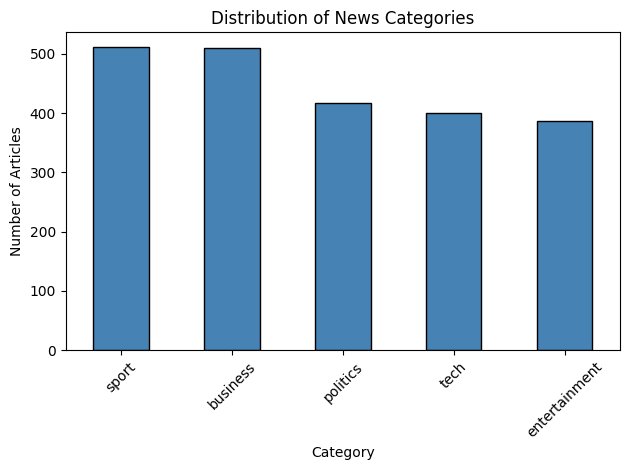

In [15]:
# Category Distribution Bar Chart
df['category'].value_counts().plot(kind='bar', color='steelblue', edgecolor='black')
plt.title("Distribution of News Categories")
plt.xlabel("Category")
plt.ylabel("Number of Articles")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('category_distribution.png', dpi=150)
plt.show()

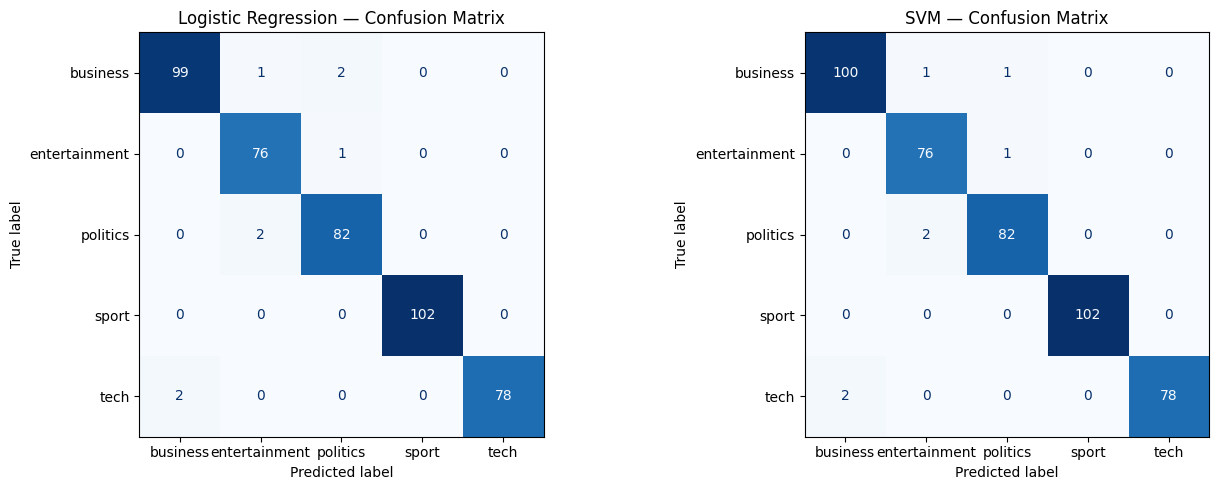

In [16]:
# Confusion Matrices for both models
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, preds, title in zip(axes,
                             [lr_preds, svm_preds],
                             ['Logistic Regression', 'SVM']):
    cm = confusion_matrix(y_test, preds)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(f'{title} — Confusion Matrix')

plt.tight_layout()
plt.savefig('confusion_matrices.png', dpi=150)
plt.show()

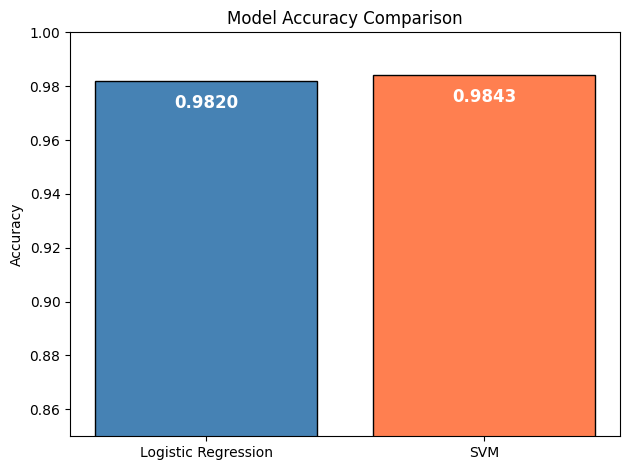

In [17]:
# Model Accuracy Comparison Bar Chart
model_names = ['Logistic Regression', 'SVM']
accuracies = [
    accuracy_score(y_test, lr_preds),
    accuracy_score(y_test, svm_preds)
]

bars = plt.bar(model_names, accuracies, color=['steelblue', 'coral'], edgecolor='black')
plt.ylim(0.85, 1.0)
plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy")

for bar, acc in zip(bars, accuracies):
    plt.text(bar.get_x() + bar.get_width() / 2,
             bar.get_height() - 0.005,
             f'{acc:.4f}', ha='center', va='top', fontsize=12, color='white', fontweight='bold')

plt.tight_layout()
plt.savefig('model_comparison.png', dpi=150)
plt.show()

## Step 6: Result Interpretation

**Model Performance Summary:**
- Logistic Regression Accuracy: 98.20%
- SVM Accuracy: 98.43% 

**Confusion Matrix Observations:**
- Sport was the easiest to classify 102/102, zero mistakes on either model
- Tech got confused with business 2 times on both models (makes sense, tech companies = business news)
- Politics got confused with entertainment 2 times, probably celebrity/political crossover articles
- Entertainment was the hardest, smallest dataset and 1 misclassification each model

**Strengths:**
- TF-IDF effectively captures word importance across documents
- Both models are well-suited to high-dimensional sparse text data
- The BBC dataset is balanced, reducing bias toward any one category

**Limitations:**
- TF-IDF does not capture word order or semantic meaning
- The model may struggle with articles that span multiple topics

**Potential Improvements:**
- Use word embeddings (Word2Vec, GloVe) or transformer models (BERT)
- Apply cross-validation for more robust performance estimates
- Tune hyperparameters (e.g., C value in SVM)